# 검출·분류 모델 비교 (MVTec Screws)

**목적:** 지금 쓰는 OpenCV 규칙 방식(A)을 기준선으로, 학습 기반 방식(B·C·D)이 얼마나 나은지 **같은 데이터·같은 기준**으로 비교한다.
결정 배경과 규칙은 [DECISIONS.md 11절](../docs/DECISIONS.md), 담당은 팀원 1 (동경), 3·4주차 병행.

| 방식 | 무엇을 하나 | 검출 | 분류 |
|---|---|---|---|
| **A. 규칙 (지금)** | 이진화 → 윤곽선 → `minAreaRect` → 장축/단축 비 ≤ 1.5 면 너트 | 규칙 | 규칙 (나사/너트 2종만) |
| **B. 형상 특징 + 고전 ML** | 부품마다 크기·모양·색 특징 → k-NN / SVM / 랜덤포레스트 | A 와 같음 | 학습 (13종) |
| **C. CNN 분류기** | 부품 영역을 잘라 ResNet18(사전학습) 로 분류 | A 와 같음 | 학습 (13종) |
| **D. YOLOv8n-OBB** | 회전 박스 검출 + 분류를 한 번에 학습 | 학습 | 학습 (13종) |

**데이터:** MVTec Screws (나사·너트 13종, 384장, 나무 배경). 원래 논문 분할 train 269 / val 55 / test 60장을 그대로 쓴다.
설정·모델 선택은 **val 로만** 하고, test 는 마지막 비교에서만 쓴다.

**환경:** GPU 없음 (Intel 내장 그래픽). 학습·추론 모두 CPU (i5-12400, 6코어). 학습 패키지는 ROS 와 분리한 `.venv-ml` (SETUP.md Step 8).

**주의:** MVTec 은 나무 배경에 부품이 많이 겹친, 우리 작업 시트보다 **훨씬 어려운** 사진이다. 여기 숫자가 실제 시연 성능은 아니다 (마지막 절).

### 왜 이 4가지인가

**한 단계에 한 가지씩만 바꾸는 사다리**로 골랐다. 성능이 바뀌면 무엇 때문인지 알 수 있게.

| 단계 | 바꾸는 것 | 답하려는 질문 |
|---|---|---|
| A → B | 분류만 규칙 → 손으로 만든 특징 + 학습 (검출은 그대로) | 틀리는 원인이 분류인가? |
| B → C | 특징을 사진에서 직접 학습 (검출은 그대로) | 손으로 만든 특징으로 부족한가? |
| → D | 검출까지 학습 | 붙어 있는 부품을 나눠 찾을 수 있나? |

- **B 에 셋을 둔 이유:** 원리가 다른 대표 분류기. k-NN(거리, 가장 단순), SVM(경계 여백, 작은 표 데이터에 강함), 랜덤포레스트(나무 앙상블, 특징 중요도로 설명 가능).
- **C = ResNet18:** 잘라 낸 부품 약 3천 장이라 사전학습 미세조정이 필요하고, 표준 백본 중 작아서 CPU 로 가능.
- **D = YOLOv8n-OBB:** 각도가 필요하므로 회전 박스(OBB)여야 하고, 공식 지원·사전학습 가중치가 있으며, 가장 작은 n 이라 CPU 로 학습(약 2시간)·추론(약 75 ms/장) 가능.
- 뺀 후보(XGBoost, ViT, Mask R-CNN, MMRotate, YOLO11 등)와 이유는 DECISIONS.md 11절 "후보를 이렇게 고른 이유".

In [1]:
# ---- 공통 준비: 경로, 라이브러리, 재현성 ----
import json, math, os, sys, time, warnings
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'src' / 'vision_pick_place'))   # 기존 검출 코드 (OpenCV·NumPy 만 씀, ROS 불필요)
sys.path.insert(0, str(ROOT / 'scripts'))
from vision_pick_place.camera_stream import preprocess          # A 의 전처리 (실제 vision_node 와 같은 함수)
from vision_pick_place.vision_detector import find_objects, classify_part

MVTEC = ROOT / 'data' / 'mvtec_screws'
MODELS = ROOT / 'data' / 'models'            # 가중치·캐시 (git 제외)
CACHE = MODELS / 'cache'
CACHE.mkdir(parents=True, exist_ok=True)

SEED = 0
np.random.seed(SEED)
warnings.filterwarnings('ignore', category=UserWarning)

# 한글 그래프: WSL 에는 한글 글꼴이 없어 Windows 맑은 고딕을 빌려 쓴다 (없으면 기본 글꼴)
from matplotlib import font_manager
for f in ['/mnt/c/Windows/Fonts/malgun.ttf']:
    if Path(f).exists():
        font_manager.fontManager.addfont(f)
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=f).get_name()
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

import platform, sklearn, torch, ultralytics
torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count() // 2)   # 물리 코어 수만큼
print(f'Python {platform.python_version()} | OpenCV {cv2.__version__} | NumPy {np.__version__}')
print(f'scikit-learn {sklearn.__version__} | torch {torch.__version__} (CUDA 사용 가능: {torch.cuda.is_available()}) | ultralytics {ultralytics.__version__}')
print('CPU:', platform.processor() or 'x86_64', '| 스레드', torch.get_num_threads())

Python 3.12.3 | OpenCV 5.1.0 | NumPy 2.5.4
scikit-learn 1.9.1 | torch 2.15.0+cpu (CUDA 사용 가능: False) | ultralytics 8.4.215
CPU: x86_64 | 스레드 6


## 1. 데이터 살펴보기

13종 중 **너트는 type_007, 009, 010, 011** 이다 (사진으로 확인). 우리 프로젝트는 나사/너트 2종이라
13종 정확도와 함께, 13종 예측을 나사/너트로 묶은 **2종 정확도**도 같이 잰다.
type_013 은 짧은 둥근머리 나사인데 위에서 보면 거의 동그래서(장축/단축 비 약 1.2) **규칙 A 가 너트로 착각할 후보**다.

In [2]:
SPLITS = {s: json.loads((MVTEC / f'mvtec_screws_{s}.json').read_text()) for s in ('train', 'val', 'test')}
CLASSES = [c['name'] for c in sorted(SPLITS['train']['categories'], key=lambda c: c['id'])]   # 0..12
NUT = {6, 8, 9, 10}                         # 0 부터 센 번호: type_007, 009, 010, 011
def to_binary(cls13):
    """13종 번호 → 'nut' / 'screw'"""
    return 'nut' if cls13 in NUT else 'screw'

def rect_from_bbox(bbox):
    """MVTec bbox [row, col, 장축 방향 폭, 높이, phi(rad)] → OpenCV RotatedRect. evaluate_detector.py 와 같은 변환."""
    row, col, w, h, phi = bbox
    return ((col - 0.5, row - 0.5), (w, h), -math.degrees(phi))

def load_split(split):
    """이미지별 정답 목록: [{'rect', 'corners', 'cls'}]"""
    data = SPLITS[split]
    by_img = defaultdict(list)
    for a in data['annotations']:
        r = rect_from_bbox(a['bbox'])
        by_img[a['image_id']].append(dict(rect=r, corners=cv2.boxPoints(r), cls=a['category_id'] - 1))
    return [(rec['file_name'], by_img[rec['id']]) for rec in data['images']]

DATA = {s: load_split(s) for s in SPLITS}
counts = pd.DataFrame({s: Counter(g['cls'] for _, gts in DATA[s] for g in gts) for s in DATA}).sort_index()
counts.index = [f'{CLASSES[i]} ({"너트" if i in NUT else "나사"})' for i in counts.index]
counts.loc['합계'] = counts.sum()
print('사진 수:', {s: len(DATA[s]) for s in DATA})
counts

사진 수: {'train': 269, 'val': 55, 'test': 60}


,train,val,test
type_001 (나사),219,47,47
type_002 (나사),219,47,48
type_003 (나사),221,47,49
type_004 (나사),220,47,48
type_005 (나사),269,59,59
type_006 (나사),270,60,63
type_007 (너트),252,58,55
type_008 (나사),254,58,55
type_009 (너트),231,44,45
type_010 (너트),250,46,51


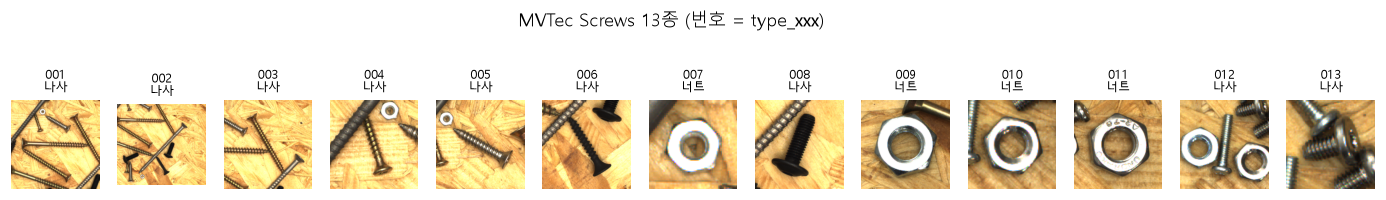

In [3]:
# 종류별 예시 (train 에서 하나씩 잘라 봄). 종류끼리 길이·머리 모양·색이 다르다.
def crop_square(img, rect, side=None):
    (cx, cy), (w, h), _ = rect
    s = int(side or max(w, h) * 0.65) + 8
    return img[max(0, int(cy) - s):int(cy) + s, max(0, int(cx) - s):int(cx) + s]

fig, axes = plt.subplots(1, 13, figsize=(16, 2.2))
seen = {}
for name, gts in DATA['train']:
    for g in gts:
        if g['cls'] not in seen:
            seen[g['cls']] = (name, g['rect'])
    if len(seen) == 13:
        break
for c, ax in enumerate(axes):
    name, rect = seen[c]
    ax.imshow(cv2.cvtColor(crop_square(cv2.imread(str(MVTEC / 'images' / name)), rect), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{c + 1:03d}\n{"너트" if c in NUT else "나사"}', fontsize=8)
    ax.axis('off')
plt.suptitle('MVTec Screws 13종 (번호 = type_xxx)', y=1.05)
plt.show()

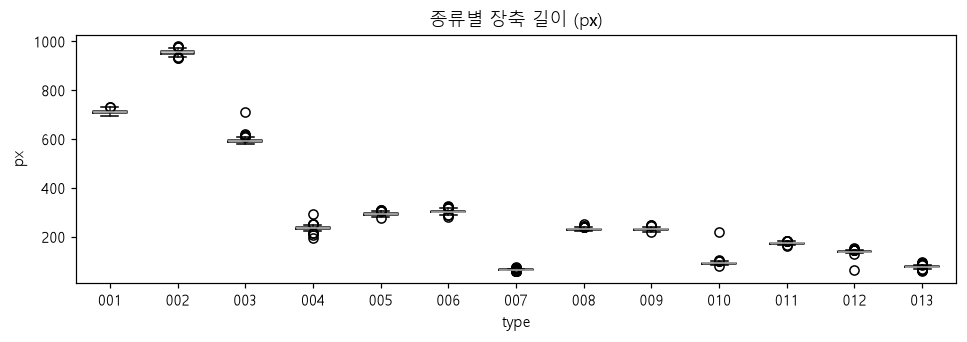

가장 작은 종류(007 너트) 장축 중앙값 66 px, 가장 긴 종류(002) 956 px


In [4]:
# 부품 크기 분포 (정답 박스 장축 길이, px). 원본은 1920×1440.
lengths = pd.DataFrame([dict(cls=f'{g["cls"] + 1:03d}', L=max(g['rect'][1])) for _, gts in DATA['train'] for g in gts])
ax = lengths.boxplot(column='L', by='cls', figsize=(10, 3), grid=False)
ax.set_title('종류별 장축 길이 (px)'); ax.set_xlabel('type'); ax.set_ylabel('px'); plt.suptitle('')
plt.show()
print('가장 작은 종류(007 너트) 장축 중앙값 %.0f px, 가장 긴 종류(002) %.0f px'
      % (lengths[lengths.cls == '007'].L.median(), lengths[lengths.cls == '002'].L.median()))

## 2. 공통 평가 방법

모든 방식을 아래 함수 하나로 채점한다 (2주차 `scripts/evaluate_detector.py` 와 같은 대응 규칙).

- **대응:** 예측 회전 박스와 정답 회전 박스의 IoU(겹친 면적 ÷ 합친 면적) ≥ 0.5 이면 후보, IoU 큰 순서로 1:1 대응.
- **검출 정밀도** = 맞힌 예측 ÷ 전체 예측 (가짜를 얼마나 안 잡나), **재현율** = 맞힌 정답 ÷ 전체 정답 (진짜를 얼마나 안 놓치나), **F1** = 둘의 조화평균.
- **분류 정확도:** 대응된 것 중 종류를 맞힌 비율 (13종 / 나사·너트 2종).
- **종합 F1 (2종):** 검출도 맞고 나사/너트도 맞아야 정답으로 센다. **로봇이 실제로 쓰는 결과**에 가장 가까운 숫자.
- **중심 오차(px), 각도 오차(°):** 대응된 것만. 각도는 장축/단축 비 > 1.5 인 정답만 (너트는 각도가 없음). 오차는 `min(|Δ|, 180−|Δ|)`.
- **틀린 유형:** 놓친 정답은 "다른 부품과 합쳐짐 / 박스 어긋남 / 아예 못 찾음", 잘못 잡은 예측은 "여러 부품을 한 박스로 / 일부·어긋남 / 배경".

In [5]:
def long_axis_deg(corners):
    """회전 박스 꼭짓점 4개 → 장축 각도 [0, 180)"""
    c = np.asarray(corners, dtype=float)
    e1, e2 = c[1] - c[0], c[2] - c[1]
    v = e1 if np.linalg.norm(e1) >= np.linalg.norm(e2) else e2
    return math.degrees(math.atan2(v[1], v[0])) % 180

def aspect(corners):
    c = np.asarray(corners, dtype=float)
    a, b = np.linalg.norm(c[1] - c[0]), np.linalg.norm(c[2] - c[1])
    return max(a, b) / max(min(a, b), 1e-6)

def angle_err(a, b):
    d = abs(a - b) % 180
    return min(d, 180 - d)

def iou_matrix(preds, gts):
    """IoU 와 '정답 중 예측이 덮은 비율' 행렬"""
    iou = np.zeros((len(preds), len(gts))); cover = np.zeros_like(iou)
    for i, p in enumerate(preds):
        pc = np.asarray(p['corners'], np.float32); pa = cv2.contourArea(pc)
        for j, g in enumerate(gts):
            gc = np.asarray(g['corners'], np.float32); ga = cv2.contourArea(gc)
            inter, _ = cv2.intersectConvexConvex(pc, gc)
            iou[i, j] = inter / (pa + ga - inter) if pa + ga - inter > 0 else 0
            cover[i, j] = inter / ga if ga > 0 else 0
    return iou, cover

def evaluate(pred_by_image, split='test', name=''):
    """pred_by_image: {파일명: [{'corners', 'cls13'(없으면 None), 'cls2'}]} → 지표 dict"""
    tp = n_pred = n_gt = 0
    ok13 = ok2 = n13 = 0
    e2e_tp = 0
    centers, angles = [], []
    fn_kind, fp_kind = Counter(), Counter()
    conf13 = np.zeros((13, 13), int)
    for fname, gts in DATA[split]:
        preds = pred_by_image.get(fname, [])
        iou, cover = iou_matrix(preds, gts)
        pairs = sorted(((iou[i, j], i, j) for i in range(len(preds)) for j in range(len(gts)) if iou[i, j] >= 0.5), reverse=True)
        up, ut = {}, set()
        for _, i, j in pairs:
            if i in up or j in ut:
                continue
            up[i] = j; ut.add(j)
        n_pred += len(preds); n_gt += len(gts); tp += len(up)
        for i, j in up.items():
            p, g = preds[i], gts[j]
            centers.append(float(np.linalg.norm(np.mean(p['corners'], 0) - np.mean(g['corners'], 0))))
            if aspect(g['corners']) > 1.5:
                angles.append(angle_err(long_axis_deg(p['corners']), long_axis_deg(g['corners'])))
            if p.get('cls13') is not None:
                n13 += 1; ok13 += p['cls13'] == g['cls']; conf13[g['cls'], p['cls13']] += 1
            hit2 = p['cls2'] == to_binary(g['cls'])
            ok2 += hit2; e2e_tp += hit2
        for i in range(len(preds)):
            if i in up:
                continue
            if (cover[i] >= 0.5).sum() >= 2: fp_kind['여러 부품을 한 박스로'] += 1
            elif iou[i].max(initial=0) > 0.1: fp_kind['일부·어긋남'] += 1
            else: fp_kind['배경'] += 1
        for j in range(len(gts)):
            if j in ut:
                continue
            if any(cover[i, j] >= 0.5 and (cover[i] >= 0.5).sum() >= 2 for i in range(len(preds))): fn_kind['다른 부품과 합쳐짐'] += 1
            elif len(preds) and iou[:, j].max() > 0.1: fn_kind['박스 어긋남'] += 1
            else: fn_kind['아예 못 찾음'] += 1
    P = tp / n_pred if n_pred else 0; R = tp / n_gt
    eP = e2e_tp / n_pred if n_pred else 0; eR = e2e_tp / n_gt
    return dict(방식=name, 예측=n_pred, 정답=n_gt, 정밀도=P, 재현율=R, F1=2 * P * R / (P + R) if P + R else 0,
                분류13=ok13 / n13 if n13 else np.nan, 분류2=ok2 / tp if tp else 0,
                종합F1_2종=2 * eP * eR / (eP + eR) if eP + eR else 0,
                중심오차px=np.mean(centers), 각도오차deg=np.mean(angles),
                _fn=dict(fn_kind), _fp=dict(fp_kind), _conf13=conf13)

# 채점 함수 자체 확인: 정답을 그대로 넣으면 모두 1.0 이어야 한다
perfect = {f: [dict(corners=g['corners'], cls13=g['cls'], cls2=to_binary(g['cls'])) for g in gts] for f, gts in DATA['test']}
r = evaluate(perfect, name='정답 그대로')
assert abs(r['F1'] - 1) < 1e-9 and r['분류13'] == 1 and r['각도오차deg'] < 1e-6
print('채점 함수 확인 OK')

채점 함수 확인 OK


## 3. A. 규칙 방식 (지금 `vision_node` 가 쓰는 것)

2주차에 val 로 골라 둔 설정 두 가지를 그대로 쓴다 (새로 조정하지 않음).
- **A-gray:** 그레이스케일 + 고정 임계값 100 (흰 배경용 기본 방식)
- **A-hsv:** `metal_hsv` (채도 ≤ 70 또는 명도 ≤ 90 = 금속·어두운 부품) + close/open 3×3. MVTec 나무 배경용

분류는 `classify_part`: 장축/단축 비 ≤ 1.5 → 너트. **13종은 구분하지 못한다** (그래서 13종 정확도 칸은 비어 있음).

In [6]:
A_SETTINGS = {
    'A-gray': dict(blur_ksize=5, threshold=100, segmentation_mode='gray'),
    'A-hsv': dict(blur_ksize=5, threshold=-1, segmentation_mode='metal_hsv', hsv_max_saturation=70,
                  hsv_max_dark_value=90, close_ksize=3, open_ksize=3),
}
IMG_CACHE = {}
def imread(fname):
    if fname not in IMG_CACHE:
        IMG_CACHE[fname] = cv2.imread(str(MVTEC / 'images' / fname))
    return IMG_CACHE[fname]

def run_rule(split, setting):
    """규칙 검출. 반환: 예측 dict, 이미지당 처리 시간(ms) 목록"""
    preds, times = {}, []
    for fname, _ in DATA[split]:
        img = imread(fname)
        t0 = time.perf_counter()
        dets = find_objects(preprocess(img, **setting), 500)
        out = [dict(corners=d.box_px.astype(np.float32), cls13=None, cls2=classify_part(d)) for d in dets]
        times.append((time.perf_counter() - t0) * 1000)
        preds[fname] = out
    return preds, times

RESULTS, TIMES, PREDS = [], {}, {}
for name, setting in A_SETTINGS.items():
    PREDS[name], TIMES[name] = run_rule('test', setting)
    RESULTS.append(evaluate(PREDS[name], name=name))
show_cols = ['방식', '예측', '정답', '정밀도', '재현율', 'F1', '분류13', '분류2', '종합F1_2종', '중심오차px', '각도오차deg']
pd.DataFrame(RESULTS)[show_cols].round(3)

,방식,예측,정답,정밀도,재현율,F1,분류13,분류2,종합F1_2종,중심오차px,각도오차deg
0,A-gray,979,661,0.428,0.634,0.511,NaN,0.890,0.455,14.617,5.461
1,A-hsv,710,661,0.776,0.834,0.804,NaN,0.929,0.747,9.503,5.197


**읽는 법:** A-hsv 의 정밀도·재현율이 2주차 기록(77.6% / 83.4%)과 같으면 채점 함수가 기존과 일치하는 것이다.
규칙의 나사/너트 분류(분류2) 는 검출이 맞은 것 중에서의 정확도다.

## 4. B. 형상 특징 + 고전 머신러닝 (k-NN / SVM / 랜덤포레스트)

부품 하나마다 회전 박스를 기준으로 **장축이 가로가 되게 잘라** 아래 특징 22개를 뽑는다.

| 묶음 | 특징 | 왜 |
|---|---|---|
| 크기 | 장축·단축 길이, log 길이, 길이 비, 박스 면적 | 종류마다 길이가 다르다 (001 vs 003) |
| 모양 | 채움 비율, 볼록도(solidity), 구멍 수·구멍 면적 비, 양 끝 굵기 비(머리 쪽) | 너트는 구멍, 나사는 한쪽에 머리 |
| 윤곽 | Hu 모멘트 7개 (log) | 회전·크기에 무관한 모양 요약 |
| 색·질감 | 부품 픽셀의 채도·명도 평균·표준편차, 밝기 표준편차 | 검정/금색/은색 나사 구분 |

- **학습:** train 의 정답 박스에서 뽑은 특징. **설정 선택:** val 정확도. **test:** 마지막에 한 번.
- 두 가지로 잰다: ① **정답 박스로 분류만** (검출이 완벽하다면 분류기가 얼마나 맞히나) ② **A-hsv 검출 박스 + 분류** (실제로 쓸 때)

In [7]:
HSV_MASK = A_SETTINGS['A-hsv']

def aligned_crop(img, rect, scale_long=1.1, scale_short=1.3, pad=6, square=False, out=None):
    """회전 박스 영역을 장축이 가로가 되도록 잘라 낸다. square=True 면 정사각형(장축 기준)으로."""
    (cx, cy), (w, h), ang = rect
    if w < h:
        w, h, ang = h, w, ang + 90           # 장축이 width 가 되게
    M = cv2.getRotationMatrix2D((cx, cy), ang, 1.0)   # ang 만큼 돌리면 장축이 가로가 된다
    if square:
        W = H = int(w * scale_long) + 2 * pad
    else:
        W, H = int(w * scale_long) + 2 * pad, int(h * scale_short) + 2 * pad
    M[:, 2] += (W / 2 - cx, H / 2 - cy)
    crop = cv2.warpAffine(img, M, (W, H), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    return cv2.resize(crop, out) if out else crop

# 잘라 내기 방향 확인: 정답 박스 꼭짓점을 같은 변환에 넣으면 가로로 누운 박스가 되어야 한다
_r = DATA['train'][0][1][0]['rect']
(_cx, _cy), (_w, _h), _a = _r
_ang = _a + 90 if _w < _h else _a
_M = cv2.getRotationMatrix2D((_cx, _cy), _ang, 1.0)
_c = cv2.transform(cv2.boxPoints(_r)[None], _M)[0]
assert abs(np.ptp(_c[:, 0]) - max(_w, _h)) < 1 and abs(np.ptp(_c[:, 1]) - min(_w, _h)) < 1
print('잘라 내기 방향 확인 OK')

FEATURE_NAMES = (['장축', '단축', 'log장축', '길이비', '박스면적', '채움비율', '볼록도', '구멍수', '구멍면적비', '끝굵기비']
                 + [f'Hu{i}' for i in range(1, 8)] + ['S평균', 'S표준편차', 'V평균', 'V표준편차', '밝기표준편차'])

def shape_features(img, rect):
    """부품 하나의 특징 벡터"""
    (_, _), (w, h), _ = rect
    L, W = max(w, h), min(w, h)
    crop = aligned_crop(img, rect)
    mask = preprocess(crop, **HSV_MASK) > 0
    f = [L, W, math.log(L), L / max(W, 1), L * W]
    fill = mask.mean()
    cnts, hier = cv2.findContours(mask.astype(np.uint8), cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        k = int(np.argmax([cv2.contourArea(c) for c in cnts])); c = cnts[k]
        area = cv2.contourArea(c); hull = cv2.contourArea(cv2.convexHull(c))
        holes = [cv2.contourArea(cnts[i]) for i in range(len(cnts)) if hier[0][i][3] == k]
        holes = [a for a in holes if a > 0.02 * area]
        hu = cv2.HuMoments(cv2.moments(c)).ravel()
        hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
        solidity, n_holes, hole_ratio = area / max(hull, 1), len(holes), sum(holes) / max(area, 1)
    else:
        hu, solidity, n_holes, hole_ratio = np.zeros(7), 0, 0, 0
    prof = mask.mean(axis=0)                      # 장축 방향 굵기 분포
    n = max(len(prof) // 6, 1)
    ends = max(prof[:n].mean(), prof[-n:].mean()); mid = prof[2 * n:-2 * n].mean() if len(prof) > 4 * n else prof.mean()
    f += [fill, solidity, n_holes, hole_ratio, ends / max(mid, 1e-3)]
    f += list(hu)
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV); gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    fg = mask if mask.any() else np.ones_like(mask)
    f += [hsv[..., 1][fg].mean(), hsv[..., 1][fg].std(), hsv[..., 2][fg].mean(), hsv[..., 2][fg].std(), gray[fg].std()]
    return np.array(f, np.float32)

def features_for(split, boxes='gt'):
    """boxes='gt': 정답 박스 (X, y). boxes='A-hsv': 검출 박스 → 이미지별 특징 목록"""
    cache = CACHE / f'feat_{split}_{boxes}.npz'
    if boxes == 'gt':
        if cache.exists():
            z = np.load(cache); return z['X'], z['y']
        X, y = [], []
        for fname, gts in DATA[split]:
            img = imread(fname)
            for g in gts:
                X.append(shape_features(img, g['rect'])); y.append(g['cls'])
        X, y = np.array(X), np.array(y)
        np.savez(cache, X=X, y=y)
        return X, y
    out = {}
    for fname, _ in DATA[split]:
        img = imread(fname)
        out[fname] = [shape_features(img, cv2.minAreaRect(p['corners'])) for p in PREDS[boxes][fname]]
    return out

t0 = time.perf_counter()
Xtr, ytr = features_for('train'); Xva, yva = features_for('val'); Xte, yte = features_for('test')
print(f'특징 추출: train {Xtr.shape}, val {Xva.shape}, test {Xte.shape} ({time.perf_counter() - t0:.0f}초, 캐시 있으면 바로)')

잘라 내기 방향 확인 OK
특징 추출: train (3119, 22), val (647, 22), test (661, 22) (0초, 캐시 있으면 바로)


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 후보 설정. val 정확도가 가장 높은 것을 고른다 (test 는 안 봄)
CANDIDATES = {
    'B-kNN': [dict(n_neighbors=k, weights='distance') for k in (1, 3, 5, 9, 15)],
    'B-SVM': [dict(C=C, gamma=g) for C in (1, 10, 100) for g in ('scale', 0.01)],
    'B-RF': [dict(n_estimators=300, max_depth=d, min_samples_leaf=m) for d in (None, 20) for m in (1, 3)],
}
def build(name, params):
    if name == 'B-kNN': return make_pipeline(StandardScaler(), KNeighborsClassifier(**params))
    if name == 'B-SVM': return make_pipeline(StandardScaler(), SVC(kernel='rbf', **params))
    return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)

B_MODELS, B_TUNE = {}, []
for name, grid in CANDIDATES.items():
    best = None
    for params in grid:
        m = build(name, params).fit(Xtr, ytr)
        acc = (m.predict(Xva) == yva).mean()
        B_TUNE.append(dict(모델=name, 설정=str(params), val정확도=acc))
        if best is None or acc > best[0]:
            best = (acc, params, m)
    B_MODELS[name] = best[2]
    print(f'{name}: val 정확도 {best[0]:.3f}  ← {best[1]}')
pd.DataFrame(B_TUNE).sort_values(['모델', 'val정확도'], ascending=[True, False]).groupby('모델').head(3).round(3)

B-kNN: val 정확도 0.981  ← {'n_neighbors': 3, 'weights': 'distance'}


B-SVM: val 정확도 0.997  ← {'C': 1, 'gamma': 'scale'}


B-RF: val 정확도 0.995  ← {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1}


,모델,설정,val정확도
11,B-RF,"{'n_estimators': 300, 'max_depth': None, 'min_...",0.995
13,B-RF,"{'n_estimators': 300, 'max_depth': 20, 'min_sa...",0.995
12,B-RF,"{'n_estimators': 300, 'max_depth': None, 'min_...",0.994
5,B-SVM,"{'C': 1, 'gamma': 'scale'}",0.997
7,B-SVM,"{'C': 10, 'gamma': 'scale'}",0.995
8,B-SVM,"{'C': 10, 'gamma': 0.01}",0.995
1,B-kNN,"{'n_neighbors': 3, 'weights': 'distance'}",0.981
2,B-kNN,"{'n_neighbors': 5, 'weights': 'distance'}",0.978
0,B-kNN,"{'n_neighbors': 1, 'weights': 'distance'}",0.977


### B 결과 ① 정답 박스로 분류만 (검출이 완벽하다고 가정)

규칙 A 도 같은 조건에서 비교한다: 정답 박스의 장축/단축 비 ≤ 1.5 → 너트.

In [9]:
def binary_acc(pred13, y):
    return np.mean([to_binary(p) == to_binary(t) for p, t in zip(pred13, y)])

CLS_ONLY = [dict(방식='A-규칙 (비율)', 분류13=np.nan,
                 분류2=np.mean([('nut' if l / max(s, 1e-6) <= 1.5 else 'screw') == to_binary(t)
                               for (l, s), t in zip(Xte[:, :2], yte)]))]
for name, m in B_MODELS.items():
    p = m.predict(Xte)
    CLS_ONLY.append(dict(방식=name, 분류13=(p == yte).mean(), 분류2=binary_acc(p, yte)))
pd.DataFrame(CLS_ONLY).round(3)

,방식,분류13,분류2
0,A-규칙 (비율),NaN,0.932
1,B-kNN,0.970,0.995
2,B-SVM,0.992,0.998
3,B-RF,0.995,1.000


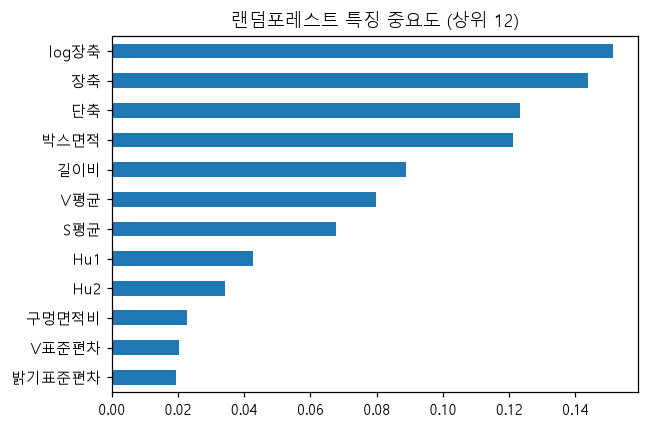

In [10]:
# 랜덤포레스트가 어떤 특징을 많이 썼나 (불순도 감소 기준 중요도)
imp = pd.Series(B_MODELS['B-RF'].feature_importances_, index=FEATURE_NAMES).sort_values()
imp.tail(12).plot.barh(figsize=(6, 4), title='랜덤포레스트 특징 중요도 (상위 12)')
plt.tight_layout(); plt.show()

### B 결과 ② A-hsv 검출 박스 + B 분류 (실제 사용 조건)

검출은 A 와 같으므로 검출 정밀도·재현율은 A-hsv 와 같고, 분류 칸만 달라진다.
처리 시간 = A 검출 시간 + 특징 추출·분류 시간.

In [11]:
best_B = max(B_MODELS, key=lambda n: (B_MODELS[n].predict(Xva) == yva).mean())
print('val 기준 가장 좋은 B:', best_B)
for name in B_MODELS:
    preds, times = {}, []
    for (fname, _), t_rule in zip(DATA['test'], TIMES['A-hsv']):
        img = imread(fname)
        t0 = time.perf_counter()
        feats = [shape_features(img, cv2.minAreaRect(p['corners'])) for p in PREDS['A-hsv'][fname]]
        cls = B_MODELS[name].predict(np.array(feats)) if feats else []
        times.append(t_rule + (time.perf_counter() - t0) * 1000)
        preds[fname] = [dict(corners=p['corners'], cls13=int(c), cls2=to_binary(int(c))) for p, c in zip(PREDS['A-hsv'][fname], cls)]
    PREDS[f'A-hsv + {name}'], TIMES[f'A-hsv + {name}'] = preds, times
    RESULTS.append(evaluate(preds, name=f'A-hsv + {name}'))
pd.DataFrame(RESULTS)[show_cols].round(3)

val 기준 가장 좋은 B: B-SVM


,방식,예측,정답,정밀도,재현율,F1,분류13,분류2,종합F1_2종,중심오차px,각도오차deg
0,A-gray,979,661,0.428,0.634,0.511,NaN,0.890,0.455,14.617,5.461
1,A-hsv,710,661,0.776,0.834,0.804,NaN,0.929,0.747,9.503,5.197
2,A-hsv + B-kNN,710,661,0.776,0.834,0.804,0.975,0.998,0.802,9.503,5.197
3,A-hsv + B-SVM,710,661,0.776,0.834,0.804,0.993,1.000,0.804,9.503,5.197
4,A-hsv + B-RF,710,661,0.776,0.834,0.804,0.993,1.000,0.804,9.503,5.197


## 5. C. CNN 분류기 (ResNet18 전이학습)

- 입력: 부품을 장축이 가로가 되게 정사각형으로 잘라 128×128 로 줄인 사진 + **실제 크기 정보**(log 장축·단축 길이).
  사진을 같은 크기로 줄이면 길이 정보가 사라져서 001(긴 나사)과 003(조금 짧은 나사)을 헷갈리므로 크기를 따로 넣는다.
- 모델: ImageNet 사전학습 ResNet18 + 크기 2개를 이어 붙인 분류층. 전부 미세조정.
- 증강: 좌우·상하 뒤집기(장축 대칭이라 같은 부품), ±8° 회전, 밝기·대비 변화.
- 학습 데이터는 B 와 같은 train 정답 박스. **val 정확도가 가장 높은 epoch** 의 가중치를 쓴다.
- CPU 학습이라 epoch 수를 작게 잡았다. 가중치가 이미 있으면 다시 학습하지 않고 불러온다 (`data/models/cnn_resnet18.pt`).

CNN 입력: (3119, 144, 144, 3) (647, 144, 144, 3) (661, 144, 144, 3)


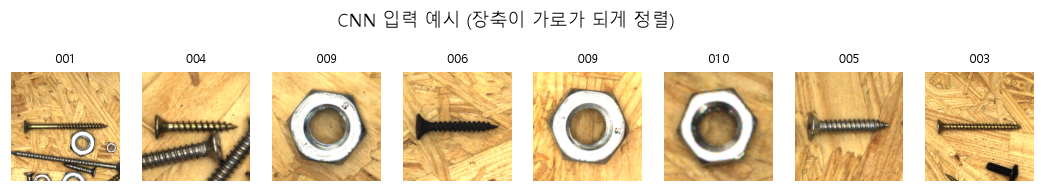

In [12]:
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset

CROP = 144      # 저장해 두는 크기 (학습 때 128 로 무작위 잘라 냄)
INP = 128

def cnn_inputs(split, boxes='gt'):
    """정사각 크롭(uint8, N×144×144×3) + 크기 특징(log L, log W) + 라벨"""
    cache = CACHE / f'cnn_{split}_{boxes}.npz'
    if boxes == 'gt' and cache.exists():
        z = np.load(cache); return z['X'], z['S'], z['y']
    X, S, y = [], [], []
    for fname, gts in DATA[split]:
        img = imread(fname)
        rects = [g['rect'] for g in gts] if boxes == 'gt' else [cv2.minAreaRect(p['corners']) for p in PREDS[boxes][fname]]
        for k, r in enumerate(rects):
            X.append(aligned_crop(img, r, scale_long=1.25, square=True, out=(CROP, CROP)))
            S.append([math.log(max(r[1])), math.log(max(min(r[1]), 1))])
            y.append(gts[k]['cls'] if boxes == 'gt' else -1)
    X, S, y = np.array(X), np.array(S, np.float32), np.array(y)
    if boxes == 'gt':
        np.savez_compressed(cache, X=X, S=S, y=y)
    return X, S, y

Ctr, Str, ctr_y = cnn_inputs('train'); Cva, Sva, cva_y = cnn_inputs('val'); Cte, Ste, cte_y = cnn_inputs('test')
S_MEAN, S_STD = Str.mean(0), Str.std(0)
print('CNN 입력:', Ctr.shape, Cva.shape, Cte.shape)

fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, i in zip(axes, np.random.RandomState(1).choice(len(Ctr), 8, replace=False)):
    ax.imshow(cv2.cvtColor(Ctr[i], cv2.COLOR_BGR2RGB)); ax.set_title(f'{ctr_y[i] + 1:03d}', fontsize=8); ax.axis('off')
plt.suptitle('CNN 입력 예시 (장축이 가로가 되게 정렬)', y=1.08); plt.show()

저장된 가중치를 불러왔다 (다시 학습하려면 파일을 지운다): cnn_resnet18.pt


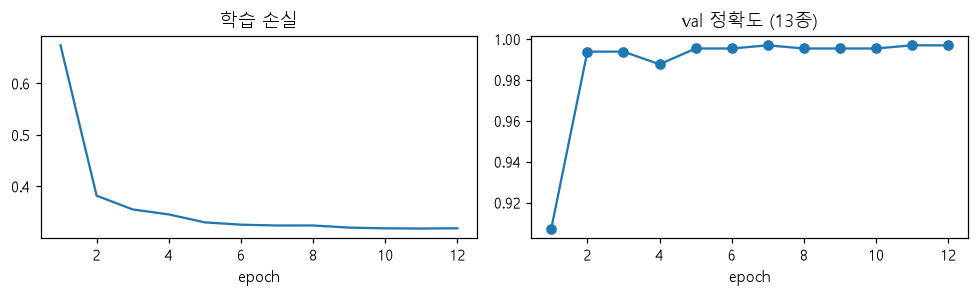

epoch 당 평균 62초, 가장 좋은 val 정확도 0.997 (epoch 7)


In [13]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_tensor(batch_bgr, train):
    """uint8 BGR 배치 → 정규화한 RGB 텐서. train 이면 증강."""
    x = torch.from_numpy(batch_bgr[..., ::-1].copy()).permute(0, 3, 1, 2).float() / 255
    if train:
        if np.random.rand() < 0.5: x = x.flip(3)
        if np.random.rand() < 0.5: x = x.flip(2)
        x = torchvision.transforms.functional.rotate(x, float(np.random.uniform(-8, 8)))
        x = x * float(np.random.uniform(0.8, 1.2)) + float(np.random.uniform(-0.08, 0.08))
        i, j = np.random.randint(0, CROP - INP + 1, 2)
    else:
        i = j = (CROP - INP) // 2
    x = x[:, :, i:i + INP, j:j + INP].clamp(0, 1)
    return (x - MEAN) / STD

class CropNet(nn.Module):
    """ResNet18 영상 특징 512개 + 크기 2개 → 13종"""
    def __init__(self, pretrained=True):
        super().__init__()
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.backbone = torchvision.models.resnet18(weights=w)
        self.backbone.fc = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(512 + 2, 13))
    def forward(self, x, s):
        return self.head(torch.cat([self.backbone(x), s], 1))

def size_tensor(S):
    return torch.from_numpy((S - S_MEAN) / S_STD).float()

@torch.no_grad()
def cnn_predict(model, X, S, bs=128):
    model.eval()
    out = [model(to_tensor(X[i:i + bs], False), size_tensor(S[i:i + bs])).argmax(1) for i in range(0, len(X), bs)]
    return torch.cat(out).numpy() if out else np.array([], int)

CNN_PATH, HIST_PATH = MODELS / 'cnn_resnet18.pt', MODELS / 'cnn_resnet18_history.json'
EPOCHS, BS = 12, 64
cnn = CropNet()
if CNN_PATH.exists():
    cnn.load_state_dict(torch.load(CNN_PATH)); history = json.loads(HIST_PATH.read_text())
    print('저장된 가중치를 불러왔다 (다시 학습하려면 파일을 지운다):', CNN_PATH.name)
else:
    opt = torch.optim.AdamW(cnn.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    lossf = nn.CrossEntropyLoss(label_smoothing=0.05)
    history, best = [], -1
    for ep in range(EPOCHS):
        cnn.train(); t0 = time.perf_counter(); perm = np.random.permutation(len(Ctr)); losses = []
        for k in range(0, len(perm), BS):
            idx = perm[k:k + BS]
            loss = lossf(cnn(to_tensor(Ctr[idx], True), size_tensor(Str[idx])), torch.from_numpy(ctr_y[idx]).long())
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        sched.step()
        va = (cnn_predict(cnn, Cva, Sva) == cva_y).mean()
        history.append(dict(epoch=ep + 1, loss=float(np.mean(losses)), val_acc=float(va), sec=time.perf_counter() - t0))
        print(f"epoch {ep + 1:2d}  loss {history[-1]['loss']:.3f}  val 정확도 {va:.3f}  ({history[-1]['sec']:.0f}초)")
        if va > best:
            best = va; torch.save(cnn.state_dict(), CNN_PATH)
    HIST_PATH.write_text(json.dumps(history))
    cnn.load_state_dict(torch.load(CNN_PATH))

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
h.plot(x='epoch', y='loss', ax=ax[0], title='학습 손실', legend=False)
h.plot(x='epoch', y='val_acc', ax=ax[1], title='val 정확도 (13종)', legend=False, marker='o')
plt.tight_layout(); plt.show()
print(f"epoch 당 평균 {h.sec.mean():.0f}초, 가장 좋은 val 정확도 {h.val_acc.max():.3f} (epoch {int(h.val_acc.idxmax()) + 1})")

In [14]:
# C 결과 ① 정답 박스로 분류만
p = cnn_predict(cnn, Cte, Ste)
CLS_ONLY.append(dict(방식='C-CNN', 분류13=(p == cte_y).mean(), 분류2=binary_acc(p, cte_y)))
C_TEST_PRED = p

# C 결과 ② A-hsv 검출 박스 + CNN
preds, times = {}, []
for (fname, _), t_rule in zip(DATA['test'], TIMES['A-hsv']):
    img = imread(fname); dets = PREDS['A-hsv'][fname]
    t0 = time.perf_counter()
    if dets:
        rects = [cv2.minAreaRect(d['corners']) for d in dets]
        X = np.array([aligned_crop(img, r, scale_long=1.25, square=True, out=(CROP, CROP)) for r in rects])
        S = np.array([[math.log(max(r[1])), math.log(max(min(r[1]), 1))] for r in rects], np.float32)
        cls = cnn_predict(cnn, X, S)
    else:
        cls = []
    times.append(t_rule + (time.perf_counter() - t0) * 1000)
    preds[fname] = [dict(corners=d['corners'], cls13=int(c), cls2=to_binary(int(c))) for d, c in zip(dets, cls)]
PREDS['A-hsv + C-CNN'], TIMES['A-hsv + C-CNN'] = preds, times
RESULTS.append(evaluate(preds, name='A-hsv + C-CNN'))
pd.DataFrame(CLS_ONLY).round(3)

,방식,분류13,분류2
0,A-규칙 (비율),NaN,0.932
1,B-kNN,0.970,0.995
2,B-SVM,0.992,0.998
3,B-RF,0.995,1.000
4,C-CNN,0.994,1.000


## 6. D. YOLOv8n-OBB (검출 + 분류를 한 번에 학습)

학습은 CPU 로 약 2시간 걸려 노트북 밖에서 `scripts/train_yolo_obb.py` 로 돌렸다 (같은 설정이 아래 표에 나온다).
이 노트북은 그 스크립트의 변환 함수·설정을 그대로 불러 쓰고, 학습 결과(`results.csv`, `best.pt`)를 읽어 **같은 채점 함수**로 평가한다.

- 사전학습: DOTA 항공사진 OBB 로 학습된 `yolov8n-obb.pt` (약 300만 파라미터, 가장 작은 크기)
- 입력 크기 1024 (원본 1920×1440). 640 이면 가장 작은 너트(장축 약 66 px)가 22 px 로 줄어서
- 증강: 회전 ±180°(부품이 아무 방향), 상하·좌우 뒤집기, 모자이크
- **신뢰도 기준(conf)** 은 val 에서 우리 채점의 F1 이 가장 높은 값으로 고른다

학습 설정: {'model': 'yolov8n-obb.pt', 'imgsz': 1024, 'epochs': 40, 'patience': 10, 'batch': 8, 'device': 'cpu', 'degrees': 180.0, 'flipud': 0.5, 'fliplr': 0.5, 'mosaic': 1.0, 'seed': 0}


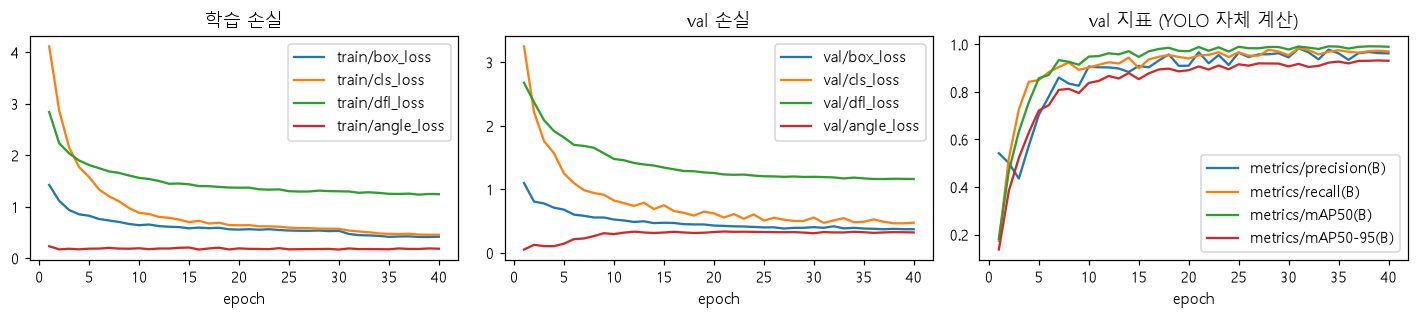

학습 epoch 40, 총 학습 시간 2.10 시간


In [15]:
import train_yolo_obb as T
from ultralytics import YOLO

RUN = MODELS / 'runs' / 'yolo_obb'
BEST = RUN / 'weights' / 'best.pt'
print('학습 설정:', {k: v for k, v in T.TRAIN_ARGS.items() if k not in ('workers', 'deterministic')})
if not BEST.exists():
    raise SystemExit('아직 학습 전입니다: .venv-ml 에서 python scripts/train_yolo_obb.py 를 먼저 실행하세요.')

res = pd.read_csv(RUN / 'results.csv'); res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
res.plot(x='epoch', y=[c for c in res.columns if c.startswith('train/')], ax=ax[0], title='학습 손실')
res.plot(x='epoch', y=[c for c in res.columns if c.startswith('val/')], ax=ax[1], title='val 손실')
res.plot(x='epoch', y=['metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)'], ax=ax[2], title='val 지표 (YOLO 자체 계산)')
plt.tight_layout(); plt.show()
print(f"학습 epoch {int(res.epoch.max())}, 총 학습 시간 {res['time'].max() / 3600:.2f} 시간" if 'time' in res else '')

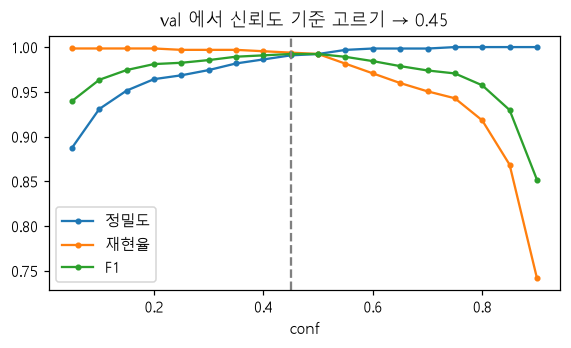

,방식,예측,정답,정밀도,재현율,F1,분류13,분류2,종합F1_2종,중심오차px,각도오차deg
0,A-gray,979,661,0.428,0.634,0.511,NaN,0.890,0.455,14.617,5.461
1,A-hsv,710,661,0.776,0.834,0.804,NaN,0.929,0.747,9.503,5.197
2,A-hsv + B-kNN,710,661,0.776,0.834,0.804,0.975,0.998,0.802,9.503,5.197
3,A-hsv + B-SVM,710,661,0.776,0.834,0.804,0.993,1.000,0.804,9.503,5.197
4,A-hsv + B-RF,710,661,0.776,0.834,0.804,0.993,1.000,0.804,9.503,5.197
5,A-hsv + C-CNN,710,661,0.776,0.834,0.804,0.984,0.989,0.795,9.503,5.197
6,D-YOLO,662,661,0.988,0.989,0.989,0.979,1.000,0.989,4.377,1.116


In [16]:
yolo = YOLO(str(BEST))
IMGSZ = T.TRAIN_ARGS['imgsz']

def run_yolo(split):
    """conf 0.01 로 한 번 예측해 두고, 기준값은 나중에 골라서 거른다. 이미지당 시간도 잰다."""
    raw, times = {}, []
    yolo.predict(imread(DATA[split][0][0]), imgsz=IMGSZ, conf=0.01, device='cpu', verbose=False)   # 첫 실행 준비(warm-up)
    for fname, _ in DATA[split]:
        img = imread(fname)
        t0 = time.perf_counter()
        r = yolo.predict(img, imgsz=IMGSZ, conf=0.01, device='cpu', verbose=False)[0]
        times.append((time.perf_counter() - t0) * 1000)
        raw[fname] = [dict(corners=c, cls13=int(k), cls2=to_binary(int(k)), conf=float(s))
                      for c, k, s in zip(r.obb.xyxyxyxy.numpy(), r.obb.cls.numpy(), r.obb.conf.numpy())]
    return raw, times

def threshold(raw, conf):
    return {f: [p for p in ps if p['conf'] >= conf] for f, ps in raw.items()}

raw_val, _ = run_yolo('val')
sweep = pd.DataFrame([dict(conf=c, **{k: v for k, v in evaluate(threshold(raw_val, c), 'val').items() if not k.startswith('_')})
                      for c in np.round(np.arange(0.05, 0.95, 0.05), 2)])
CONF = float(sweep.loc[sweep.F1.idxmax(), 'conf'])
ax = sweep.plot(x='conf', y=['정밀도', '재현율', 'F1'], figsize=(6, 3), title=f'val 에서 신뢰도 기준 고르기 → {CONF}', marker='.')
ax.axvline(CONF, color='gray', ls='--'); plt.show()

raw_test, TIMES['D-YOLO'] = run_yolo('test')
PREDS['D-YOLO'] = threshold(raw_test, CONF)
RESULTS.append(evaluate(PREDS['D-YOLO'], name='D-YOLO'))
pd.DataFrame(RESULTS)[show_cols].round(3)

## 7. 종합 비교

In [17]:
summary = pd.DataFrame(RESULTS).set_index('방식')
summary['처리시간ms'] = [np.median(TIMES[n]) for n in summary.index]
table = summary[['정밀도', '재현율', 'F1', '분류13', '분류2', '종합F1_2종', '중심오차px', '각도오차deg', '처리시간ms']]
(table.style.format({c: '{:.1%}' for c in ['정밀도', '재현율', 'F1', '분류13', '분류2', '종합F1_2종']}
                    | {'중심오차px': '{:.1f}', '각도오차deg': '{:.2f}', '처리시간ms': '{:.0f}'}, na_rep='—')
      .background_gradient(subset=['F1', '종합F1_2종'], cmap='Greens'))

,정밀도,재현율,F1,분류13,분류2,종합F1_2종,중심오차px,각도오차deg,처리시간ms
방식,,,,,,,,,
A-gray,42.8%,63.4%,51.1%,—,89.0%,45.5%,14.6,5.46,6
A-hsv,77.6%,83.4%,80.4%,—,92.9%,74.7%,9.5,5.20,23
A-hsv + B-kNN,77.6%,83.4%,80.4%,97.5%,99.8%,80.2%,9.5,5.20,157
A-hsv + B-SVM,77.6%,83.4%,80.4%,99.3%,100.0%,80.4%,9.5,5.20,39
A-hsv + B-RF,77.6%,83.4%,80.4%,99.3%,100.0%,80.4%,9.5,5.20,125
A-hsv + C-CNN,77.6%,83.4%,80.4%,98.4%,98.9%,79.5%,9.5,5.20,117
D-YOLO,98.8%,98.9%,98.9%,97.9%,100.0%,98.9%,4.4,1.12,98


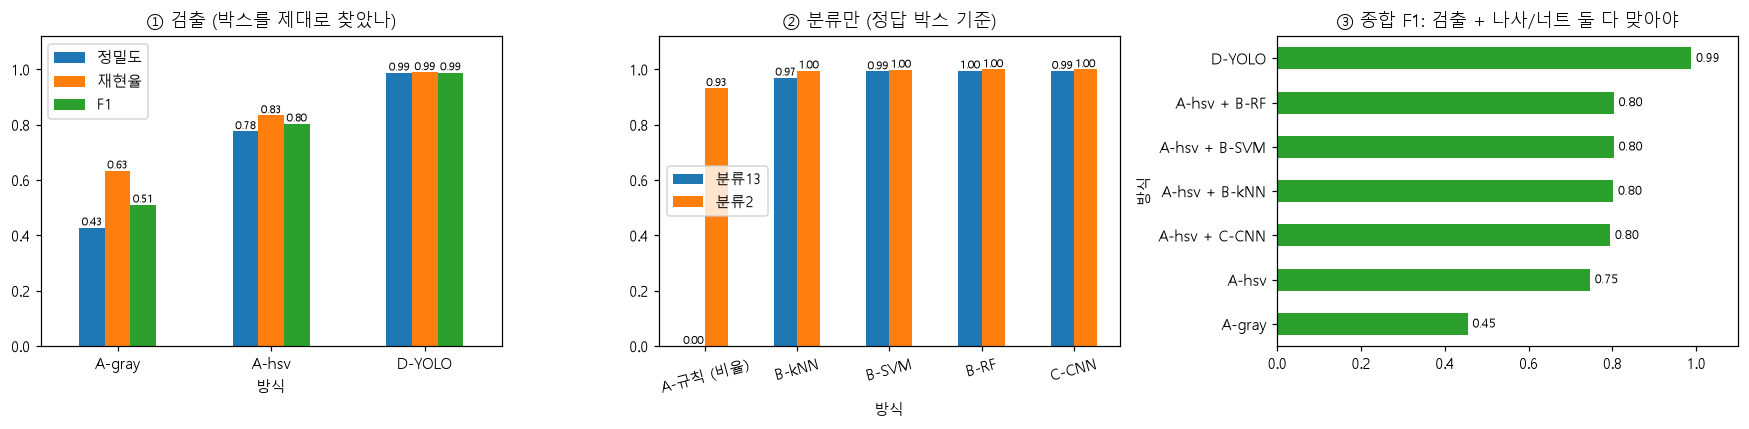

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
det = summary.loc[['A-gray', 'A-hsv', 'D-YOLO'], ['정밀도', '재현율', 'F1']]
det.plot.bar(ax=axes[0], rot=0, ylim=(0, 1.12), title='① 검출 (박스를 제대로 찾았나)')
cls = pd.DataFrame(CLS_ONLY).set_index('방식')[['분류13', '분류2']]
cls.plot.bar(ax=axes[1], rot=15, ylim=(0, 1.12), title='② 분류만 (정답 박스 기준)')
e2e = summary['종합F1_2종'].sort_values()
e2e.plot.barh(ax=axes[2], xlim=(0, 1.1), title='③ 종합 F1: 검출 + 나사/너트 둘 다 맞아야', color='tab:green')
for ax in axes[:2]:
    for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7)
for i, v in enumerate(e2e): axes[2].text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

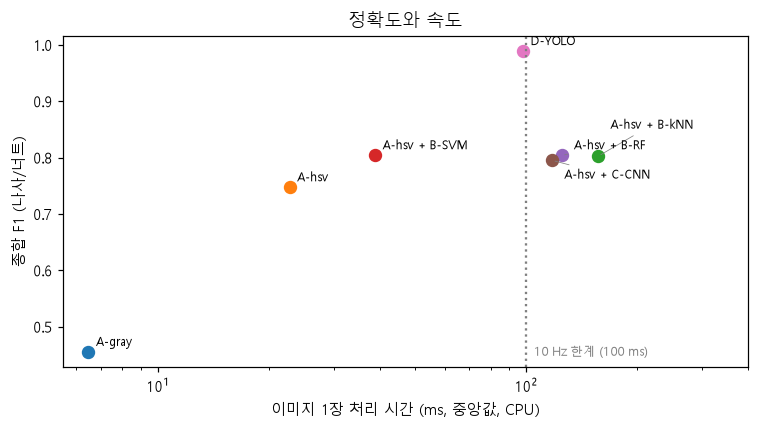

In [19]:
# 정확도 vs 속도: 오른쪽 위가 좋고, 왼쪽이 빠르다 (x 는 로그 눈금)
fig, ax = plt.subplots(figsize=(7, 4))
# 100 ms 근처에 점이 몰려 이름이 겹치므로, 오른쪽 무리는 이름을 위아래로 엇갈려 단다
crowd = 0
for n, row in summary.iterrows():
    ax.scatter(row['처리시간ms'], row['종합F1_2종'], s=60)
    off = (5, 4)
    if row['처리시간ms'] > 100 and row['종합F1_2종'] < 0.9:
        off = (8, [18, 4, -12, -26][crowd % 4]); crowd += 1
    ax.annotate(n, (row['처리시간ms'], row['종합F1_2종']), textcoords='offset points', xytext=off, fontsize=8,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.5) if off != (5, 4) else None)
ax.set_xscale('log'); ax.set_xlim(right=400); ax.set_xlabel('이미지 1장 처리 시간 (ms, 중앙값, CPU)'); ax.set_ylabel('종합 F1 (나사/너트)')
ax.axvline(100, color='gray', ls=':'); ax.text(105, ax.get_ylim()[0] + 0.02, '10 Hz 한계 (100 ms)', fontsize=8, color='gray')
ax.set_title('정확도와 속도'); plt.tight_layout(); plt.show()

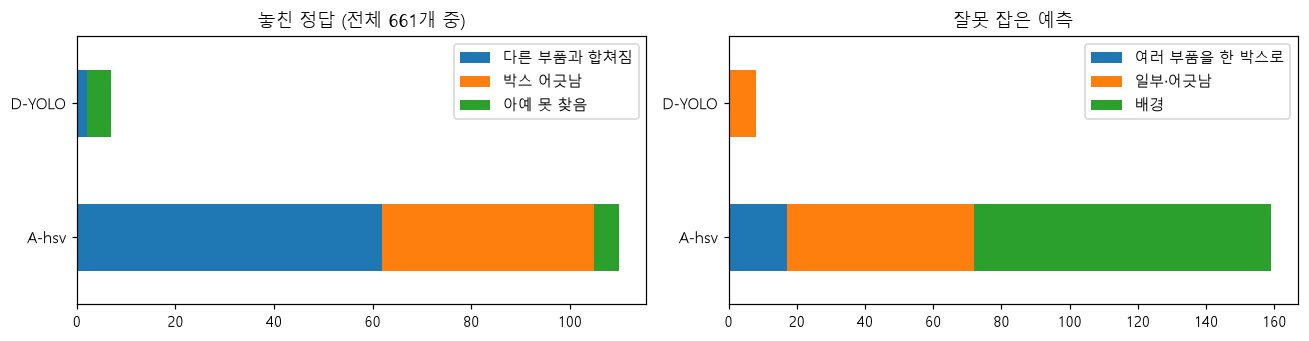

In [20]:
# 틀린 유형 비교: 규칙(A-hsv) vs 학습(D-YOLO)
kinds_fn = ['다른 부품과 합쳐짐', '박스 어긋남', '아예 못 찾음']; kinds_fp = ['여러 부품을 한 박스로', '일부·어긋남', '배경']
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
pd.DataFrame({n: [summary.loc[n, '_fn'].get(k, 0) for k in kinds_fn] for n in ['A-hsv', 'D-YOLO']}, index=kinds_fn).T \
    .plot.barh(stacked=True, ax=axes[0], title=f'놓친 정답 (전체 {summary.loc["A-hsv", "정답"]}개 중)')
pd.DataFrame({n: [summary.loc[n, '_fp'].get(k, 0) for k in kinds_fp] for n in ['A-hsv', 'D-YOLO']}, index=kinds_fp).T \
    .plot.barh(stacked=True, ax=axes[1], title='잘못 잡은 예측')
plt.tight_layout(); plt.show()

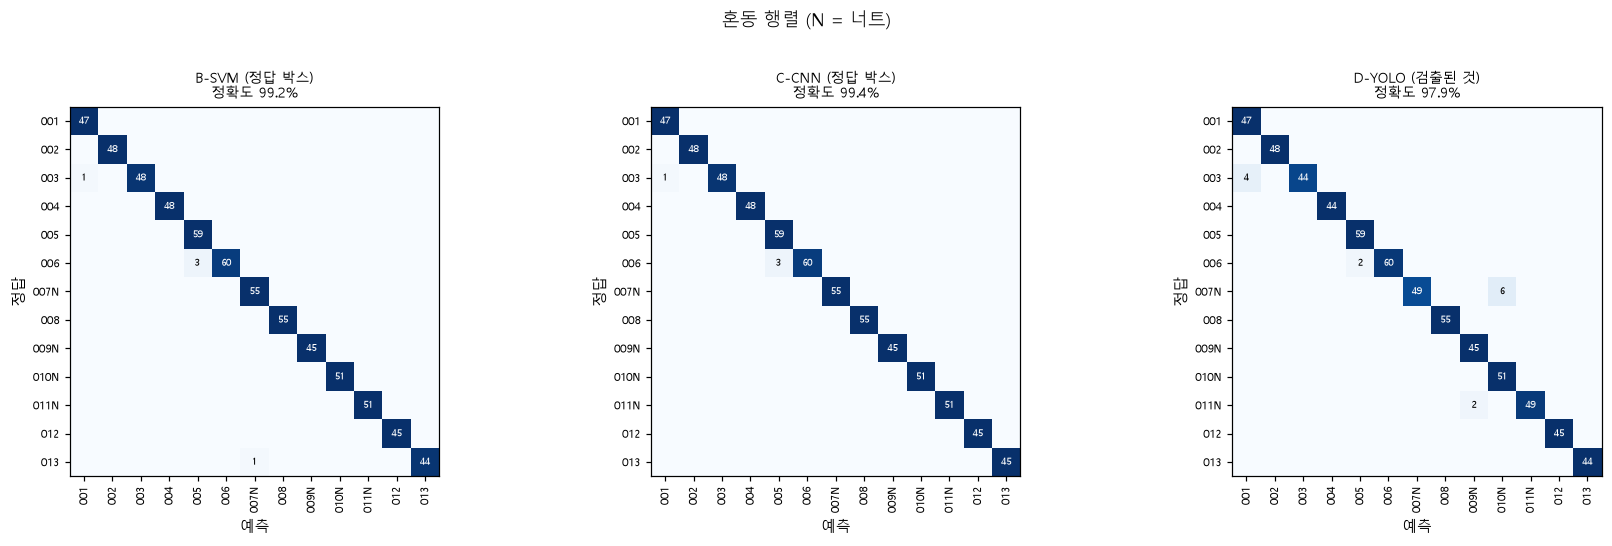

In [21]:
# 혼동 행렬 (13종, 행 = 정답, 열 = 예측, 행마다 비율). B 는 val 로 고른 최고 모델, C·D 는 그대로.
from sklearn.metrics import confusion_matrix
mats = {f'{best_B} (정답 박스)': confusion_matrix(yte, B_MODELS[best_B].predict(Xte), labels=range(13)),
        'C-CNN (정답 박스)': confusion_matrix(cte_y, C_TEST_PRED, labels=range(13)),
        'D-YOLO (검출된 것)': summary.loc['D-YOLO', '_conf13']}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ticks = [f'{i + 1:03d}{"N" if i in NUT else ""}' for i in range(13)]
for ax, (n, m) in zip(axes, mats.items()):
    mn = m / np.maximum(m.sum(1, keepdims=True), 1)
    ax.imshow(mn, cmap='Blues', vmin=0, vmax=1)
    for i in range(13):
        for j in range(13):
            if m[i, j]: ax.text(j, i, m[i, j], ha='center', va='center', fontsize=6, color='white' if mn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(13), ticks, rotation=90, fontsize=7); ax.set_yticks(range(13), ticks, fontsize=7)
    ax.set_title(f'{n}\n정확도 {np.trace(m) / m.sum():.1%}', fontsize=9); ax.set_xlabel('예측'); ax.set_ylabel('정답')
plt.suptitle('혼동 행렬 (N = 너트)', y=1.02); plt.tight_layout(); plt.show()

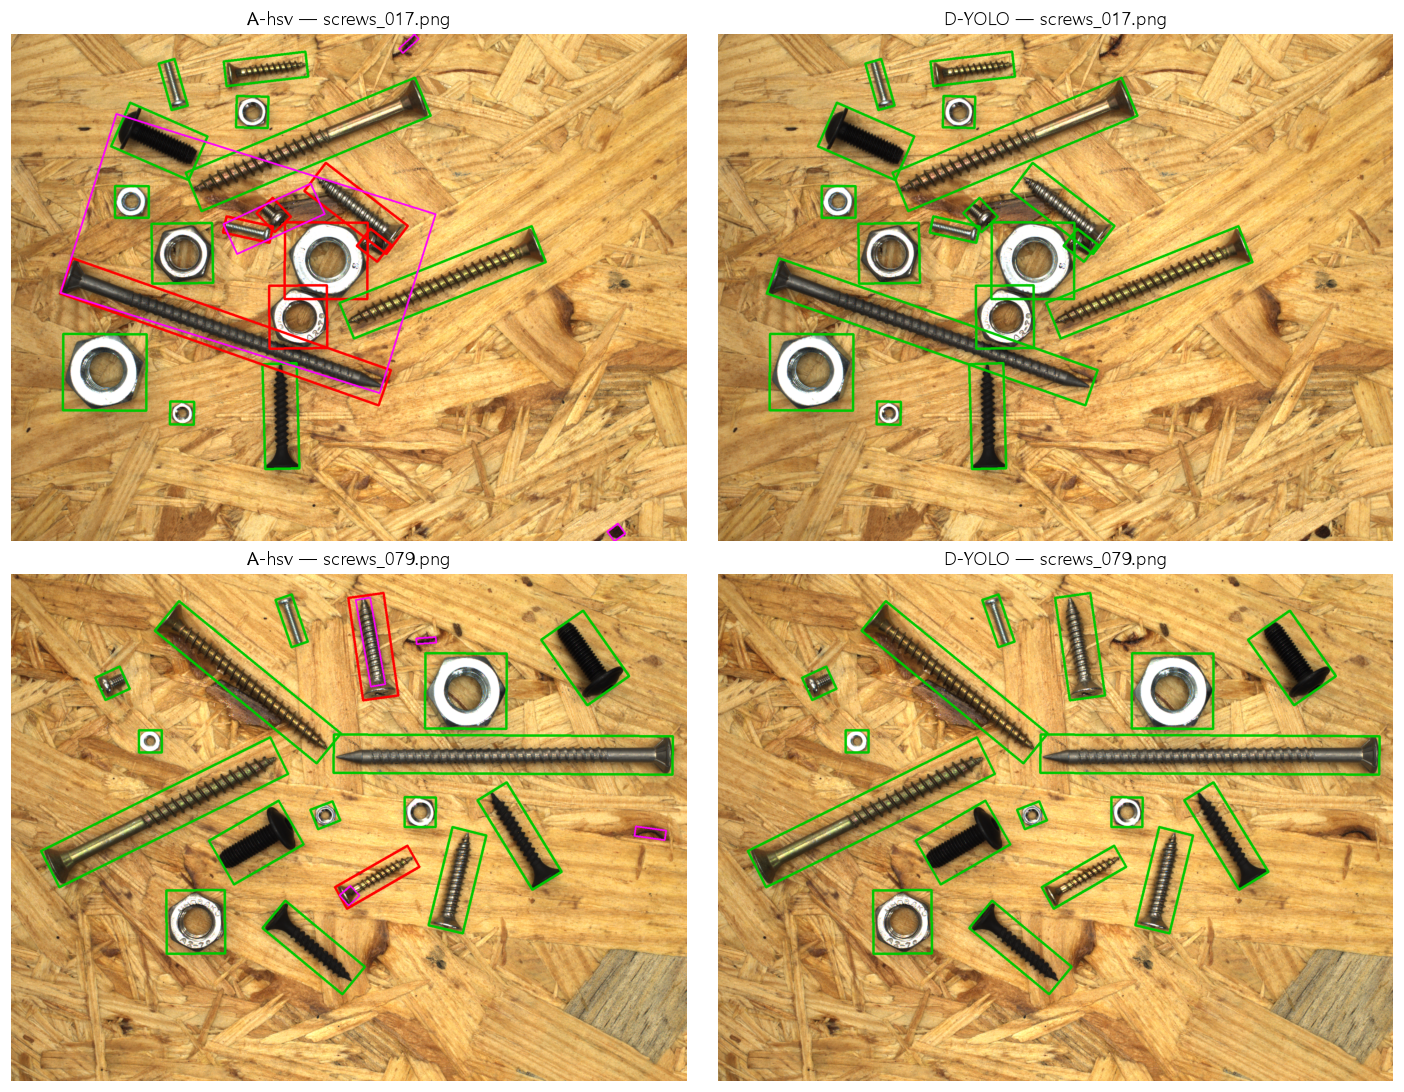

In [22]:
# 같은 사진에서 규칙 vs YOLO. 초록 = 맞힌 정답, 빨강 = 놓친 정답, 분홍 = 잘못 잡은 예측
def draw(fname, preds):
    img = imread(fname).copy(); gts = dict(DATA['test'])[fname]
    iou, _ = iou_matrix(preds, gts)
    hit_g = {j for j in range(len(gts)) if len(preds) and iou[:, j].max() >= 0.5}
    hit_p = {i for i in range(len(preds)) if len(gts) and iou[i].max() >= 0.5}
    for j, g in enumerate(gts):
        cv2.polylines(img, [g['corners'].astype(np.int32)], True, (0, 200, 0) if j in hit_g else (0, 0, 255), 5)
    for i, p in enumerate(preds):
        if i not in hit_p: cv2.polylines(img, [np.asarray(p['corners']).astype(np.int32)], True, (255, 0, 255), 4)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

worst = sorted(DATA['test'], key=lambda x: -len(x[1]))[:2]     # 부품이 가장 많이(겹쳐) 놓인 사진 2장
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for r, (fname, _) in enumerate(worst):
    for c, n in enumerate(['A-hsv', 'D-YOLO']):
        axes[r, c].imshow(draw(fname, PREDS[n][fname])); axes[r, c].axis('off'); axes[r, c].set_title(f'{n} — {fname}')
plt.tight_layout(); plt.show()

## 8. 해석과 결론

> 숫자는 모두 **MVTec test 60장(정답 661개)** 기준이고, 설정·기준값은 val 에서만 골랐다. 시간은 이 PC(CPU 6스레드)에서 잰 이미지 1장 중앙값.

| 방식 | 검출 F1 | 분류 2종 | **종합 F1** | 중심 오차 | 각도 오차 | 시간/장 |
|---|---|---|---|---|---|---|
| A-hsv (지금 `vision_node`) | 0.804 | 92.9% | **0.747** | 9.5 px | 5.2° | 23 ms |
| A-hsv + B-SVM | 0.804 | 100% | **0.804** | 9.5 px | 5.2° | 39 ms |
| A-hsv + C-CNN | 0.804 | 98.9% | **0.795** | 9.5 px | 5.2° | 117 ms |
| D-YOLOv8n-OBB | **0.989** | 100% | **0.989** | **4.4 px** | **1.1°** | 98 ms |

### ① 병목은 분류가 아니라 검출이다
- 정답 박스를 주고 분류만 시키면 B-SVM 99.2%, B-RF 99.5%, C-CNN 99.4% 로 **13종까지 거의 다 맞힌다.** 나사/너트 2종은 100%.
- 규칙(A)의 분류 오류는 거의 다 `type_013`(짧은 나사, 가로세로 비 약 1.2)을 너트로 본 것이다. B 를 붙이면 이것이 고쳐져 종합 F1 이 0.747 → 0.804 로 오른다.
- 하지만 **0.804 에서 더 오르지 못한다.** 검출 F1 이 0.804 이기 때문이다. 박스를 못 찾으면 분류를 아무리 잘해도 소용없다.

### ② YOLO 는 규칙이 못 하는 것, 즉 붙어 있는 부품 나누기를 해결했다
- 틀린 유형 그래프를 보면 규칙의 놓친 정답 110개 중 **62개가 "다른 부품과 합쳐짐"**, 잘못 잡은 159개 중 **87개가 "배경"** 이었다. YOLO 는 각각 **2개, 0개**다.
- 이는 사진 비교에서도 보인다. 규칙은 겹친 나사·너트 무리를 큰 박스 하나로 묶는다. YOLO 는 하나씩 따로 잡는다.
- 박스 품질도 좋아졌다. 중심 오차는 9.5 → 4.4 px, 각도 오차는 5.2° → 1.1° 로 줄었다. 로봇이 집을 때 그대로 영향을 주는 값이다.

### ③ CNN(C)은 비용 대비 이득이 없다
- 정답 박스 기준 정확도는 C 99.4% 로 B-SVM 99.2% 와 사실상 같다. 1장 차이다.
- 반면 학습은 12분, 추론은 약 3배 느리다. 규칙 박스로 잘라 넣으면 98.4% 로 오히려 떨어진다. 학습 때 본 깔끔한 정답 박스 조각과 모양이 달라서다.
- 결론: **분류만 바꾸려면 B-SVM 으로 충분하다.** 손으로 만든 형상 특징(실제 길이·폭·가로세로 비 등)만으로 이 문제는 이미 풀린다.

### ④ YOLO 가 틀리는 곳
- 13종 기준 97.9% 로 B·C 보다 낮다. 틀린 것은 거의 **너트끼리**다(`007`↔`010` 6개, `011`→`009` 2개). 모양이 같고 크기만 다른 너트들이다.
- YOLO 는 1024 px 로 줄인 사진에서 크기를 간접적으로만 본다. B 는 실제 크기 특징을 직접 쓴다. 그래도 나사/너트 2종은 100% 라 **집기에는 영향이 없다.**
- 필요해지면 YOLO 박스에 B-SVM 을 덧붙이는 방법(D + B)이 다음 후보다.

### ⑤ 속도
- YOLO 98 ms/장은 10 Hz(100 ms) 한계 바로 안쪽이다. 우리 노드는 매 프레임이 아니라 **집기 1회마다** 검출하므로 실사용에는 충분하다.
- k-NN(157 ms), RF(125 ms)가 SVM(39 ms)보다 느린 것은 모델 자체보다 scikit-learn 의 호출당 오버헤드 때문이다. 부품 수가 적어 1장에 한 번씩 호출하기 때문이다.

### ⑥ 이 결과를 그대로 믿으면 안 되는 점
- MVTec 은 **같은 카메라·같은 나무 배경**이다. 학습과 시험이 같은 환경이라 YOLO 에 유리하다. 우리 환경은 다르다(흰 시트, 휴대폰, 약 1.66 px/mm).
- YOLO 를 우리 환경에 쓰려면 **우리 사진으로 라벨을 만들어 다시 학습**해야 한다. 규칙(A)과 B 는 mm 단위 특징이라 옮기기 쉽다.
- 규칙의 실패는 대부분 부품이 붙거나 겹친 사진에서 났다. **부품이 떨어져 놓인 사진에서는 규칙도 거의 완벽했다**(오류 분석, DECISIONS 11절).

### 결론
1. **MVTec 기준 최고 성능은 D-YOLOv8n-OBB 다.** 종합 F1 0.99, CPU 로도 100 ms 안이다. 차이가 0.80 → 0.99 로 커서 "차이가 작으면 단순한 쪽" 규칙에 걸리지 않는다.
2. **분류 개선만 놓고 보면 B-SVM 이 가장 효율적이다.** 규칙에 붙이면 39 ms 로 `type_013` 오류가 사라진다. CNN 은 쓸 이유가 없다.
3. **실제 `vision_node` 적용은 4주차에 우리 사진으로 다시 잰 뒤 셋이 정한다.** 부품을 떨어뜨려 놓는 지금 시나리오라면 A-hsv + B-SVM 으로 충분할 가능성이 크다. 부품이 붙어 있어야 하는 시나리오라면 YOLO 를 우리 데이터로 재학습해 쓴다.